# Brand Popularity and Customer Preference Analysis
EDAV Python course-end project. Uses UCI Online Retail transaction data.

> Note: the dataset has product descriptions, not explicit brands or satisfaction ratings. We analyze product popularity and purchase behavior as proxies.

## 1. LOAD THE CSV FILE
Set file_path to the exact path of your downloaded CSV.

In [7]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/Online Retail.xlsx")

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 2.INSPECT THE DATASET

2.1. View the column names and data types

In [8]:

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


2.2. Check missing values

In [9]:

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)


Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


2.3. Check duplicate records

In [10]:

print("Total duplicate rows:", df.duplicated().sum())

print("Dataset shape:", df.shape)


Total duplicate rows: 5268
Dataset shape: (541909, 8)


2.4. View basic statistics

In [11]:

display(df.describe(include="all").T)


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. DATA CLEANING

3.1. Check the data quality

In [12]:

print("Original dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nCancelled invoices:", 
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

print("\nNon-positive quantities:", (df["Quantity"] <= 0).sum())

print("\nNon-positive prices:", (df["UnitPrice"] <= 0).sum())


Original dataset shape: (541909, 8)

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Duplicate rows: 5268

Cancelled invoices: 9288

Non-positive quantities: 10624

Non-positive prices: 2517


3.2. Remove duplicate records and prepare the data

In [13]:

# Make a copy and remove exact duplicate rows
clean_df = df.drop_duplicates().copy()

# Clean product descriptions
clean_df["Description"] = clean_df["Description"].str.strip()

# Ensure invoice dates use datetime format
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"], errors="coerce"
)

# Remove rows without essential product and transaction details
clean_df = clean_df.dropna(
    subset=["InvoiceNo", "Description", "InvoiceDate", "Quantity", "UnitPrice"]
)

# Remove blank product descriptions
clean_df = clean_df[clean_df["Description"] != ""]

print("Shape after basic cleaning:", clean_df.shape)
display(clean_df.head())


Shape after basic cleaning: (535186, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


3.3. Prepare valid sales transactions

In [14]:

sales_df = clean_df.copy()

# Remove cancelled invoices (invoice numbers beginning with C)
sales_df = sales_df[
    ~sales_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

# Keep positive quantities and prices for the main sales analysis
sales_df = sales_df[
    (sales_df["Quantity"] > 0) &
    (sales_df["UnitPrice"] > 0)
].copy()

# Calculate transaction-line revenue
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

# Extract the month for trend analysis
sales_df["Month"] = (
    sales_df["InvoiceDate"].dt.to_period("M").astype(str)
)

print("Valid sales records:", len(sales_df))
print("Cleaned sales dataset shape:", sales_df.shape)
print("Total revenue: £{:,.2f}".format(sales_df["Revenue"].sum()))

display(sales_df.head())


Valid sales records: 524878
Cleaned sales dataset shape: (524878, 10)
Total revenue: £10,642,110.80


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,2010-12
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,2010-12


3.4. Save your cleaned data

In [15]:

from pathlib import Path

output_dir = Path("../outputs/cleaned_data")
output_dir.mkdir(parents=True, exist_ok=True)

sales_df.to_csv(
    output_dir / "cleaned_retail_sales.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


## 4. ANALYZE PRODUCT POPOULARITY

4.1. Find the top 10 popular products

In [16]:

# Group sales by product description
product_analysis = (
    sales_df.groupby("Description")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Invoice_Count=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Quantity", ascending=False)
)

# Display the top 10 products by quantity sold
top_10_products = product_analysis.head(10)

display(top_10_products)


,Total_Quantity,Total_Revenue,Invoice_Count
Description,,,
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,535
JUMBO BAG RED RETROSPOT,48371,94159.81,2089
WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72,2256
POPCORN HOLDER,36749,34288.67,803
PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,1320
ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1455
RABBIT NIGHT LIGHT,30739,66870.03,994


4.2. Create your first visualization

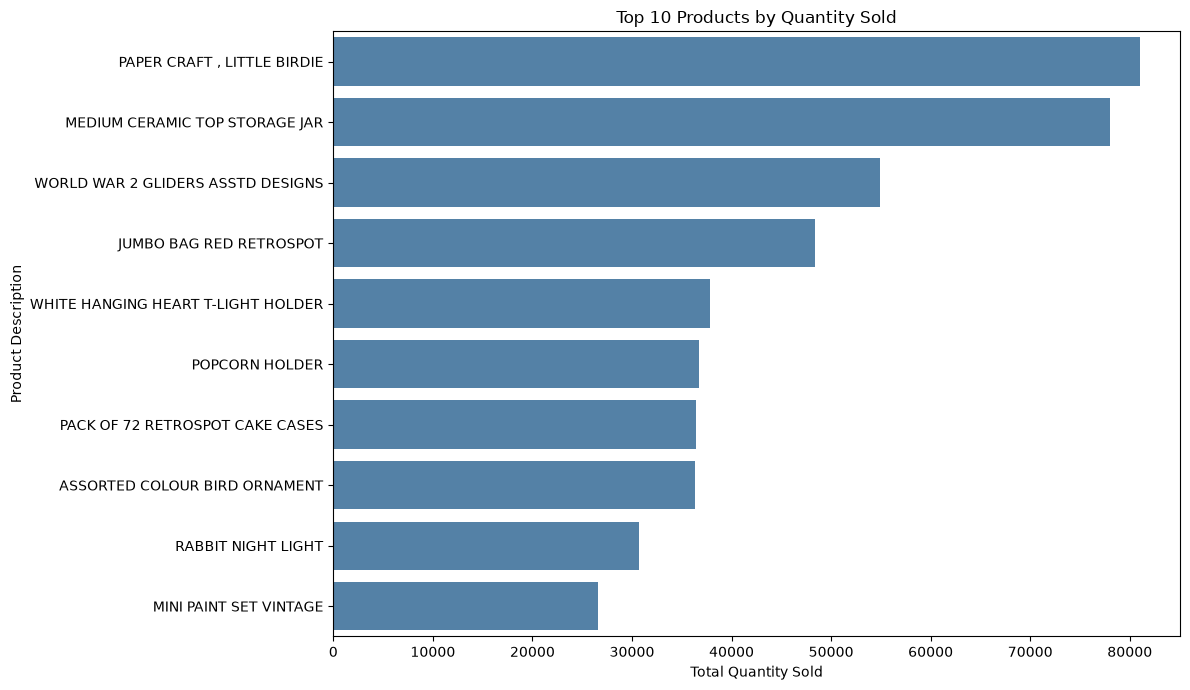

In [17]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_products.reset_index(),
    x="Total_Quantity",
    y="Description",
    color="steelblue"
)

plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Description")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


4.3. Find the highest-revenue products

In [18]:

top_10_revenue = (
    product_analysis
    .sort_values("Total_Revenue", ascending=False)
    .head(10)
)

display(top_10_revenue)


,Total_Quantity,Total_Revenue,Invoice_Count
Description,,,
DOTCOM POSTAGE,706,206248.77,706
REGENCY CAKESTAND 3 TIER,13851,174156.54,1988
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72,2256
PARTY BUNTING,18283,99445.23,1685
JUMBO BAG RED RETROSPOT,48371,94159.81,2089
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,247
POSTAGE,3150,78101.88,1126
Manual,6985,77752.82,290


4.4. Save your product analysis

In [19]:

product_analysis.to_csv(
    "../outputs/cleaned_data/product_analysis.csv"
)

print("Product analysis saved successfully!")


Product analysis saved successfully!


## 5. CUSTOMER PREFERENCE ANALYSIS

5.1. Prepare customer data

In [20]:

# CustomerID is required for customer-level analysis
customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

# Convert CustomerID into a consistent format
customer_df["CustomerID"] = customer_df["CustomerID"].astype(int).astype(str)

# Calculate customer purchasing metrics
customer_analysis = (
    customer_df.groupby("CustomerID")
    .agg(
        Total_Spending=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Purchase_Frequency=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Spending", ascending=False)
)

print("Total unique customers:", customer_analysis.shape[0])
display(customer_analysis.head(10))


Total unique customers: 4338


,Total_Spending,Total_Quantity,Purchase_Frequency
CustomerID,,,
14646,280206.02,196915,73
18102,259657.30,64124,60
17450,194390.79,69973,46
16446,168472.50,80997,2
14911,143711.17,80240,201
12415,124914.53,77374,21
14156,117210.08,57768,55
17511,91062.38,64549,31
16029,80850.84,40108,63


5.2. Visualize the top 10 customers

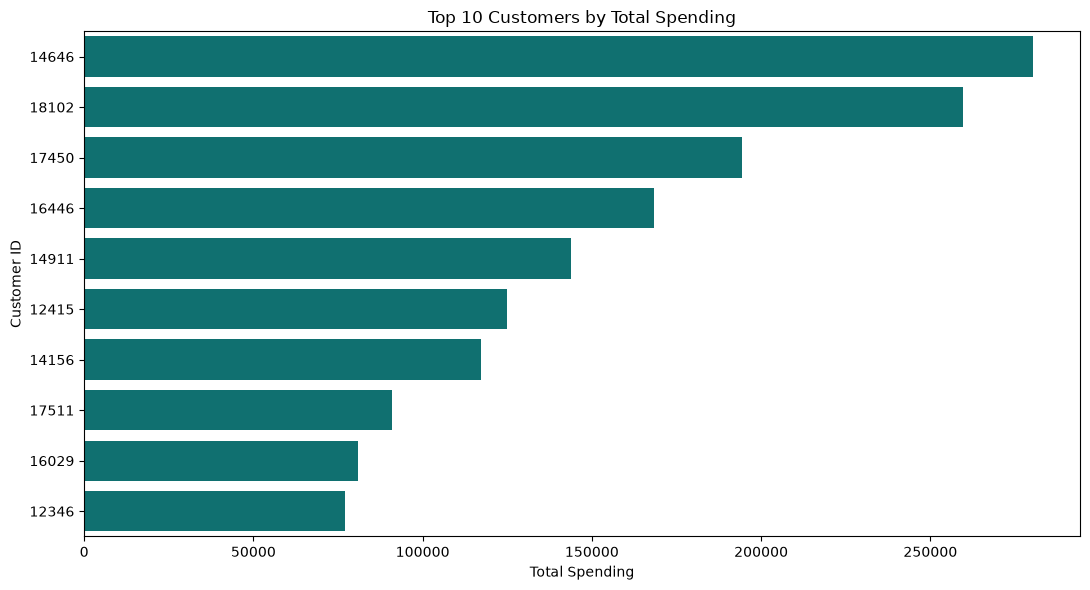

In [21]:

import matplotlib.pyplot as plt
import seaborn as sns

top_10_customers = customer_analysis.head(10).reset_index()

plt.figure(figsize=(11, 6))

sns.barplot(
    data=top_10_customers,
    x="Total_Spending",
    y="CustomerID",
    color="teal"
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/top_10_customers.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


5.3. Analyze purchase frequency

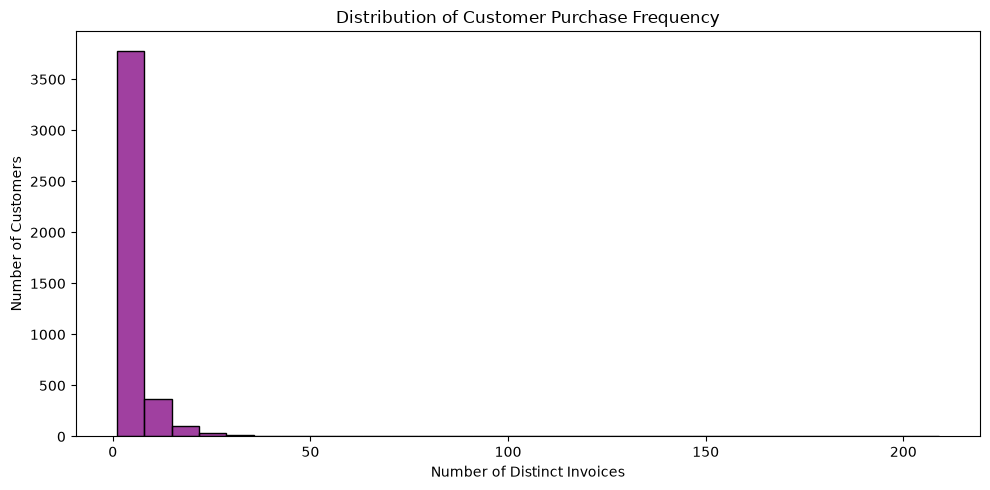

Purchase_Frequency
1     1493
2      835
3      508
4      388
5      242
6      172
7      143
8       98
9       68
10      54
11      52
12      45
13      30
14      20
15      28
Name: count, dtype: int64

In [22]:

frequency_counts = (
    customer_analysis["Purchase_Frequency"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 5))

sns.histplot(
    customer_analysis["Purchase_Frequency"],
    bins=30,
    color="purple"
)

plt.title("Distribution of Customer Purchase Frequency")
plt.xlabel("Number of Distinct Invoices")
plt.ylabel("Number of Customers")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/customer_purchase_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(frequency_counts.head(15))


5.4. Save the customer analysis

In [23]:

customer_analysis.to_csv(
    "../outputs/cleaned_data/customer_analysis.csv"
)

print("Customer analysis saved successfully!")
print("Customer results:", len(customer_analysis))


Customer analysis saved successfully!
Customer results: 4338


## 6. ANALYSE MONTHLY SALES TRENDS

In [24]:

monthly_sales = (
    sales_df.groupby("Month")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("Month")
)

display(monthly_sales)


,Month,Total_Revenue,Total_Quantity,Unique_Invoices
0,2010-12,821452.730,358019,1559
1,2011-01,689811.610,387099,1086
2,2011-02,522545.560,282934,1100
3,2011-03,716215.260,376599,1454
4,2011-04,536968.491,307953,1246
5,2011-05,769296.610,395001,1681
6,2011-06,760547.010,388511,1533
7,2011-07,718076.121,399693,1475
8,2011-08,757841.380,421020,1361
9,2011-09,1056435.192,569573,1837


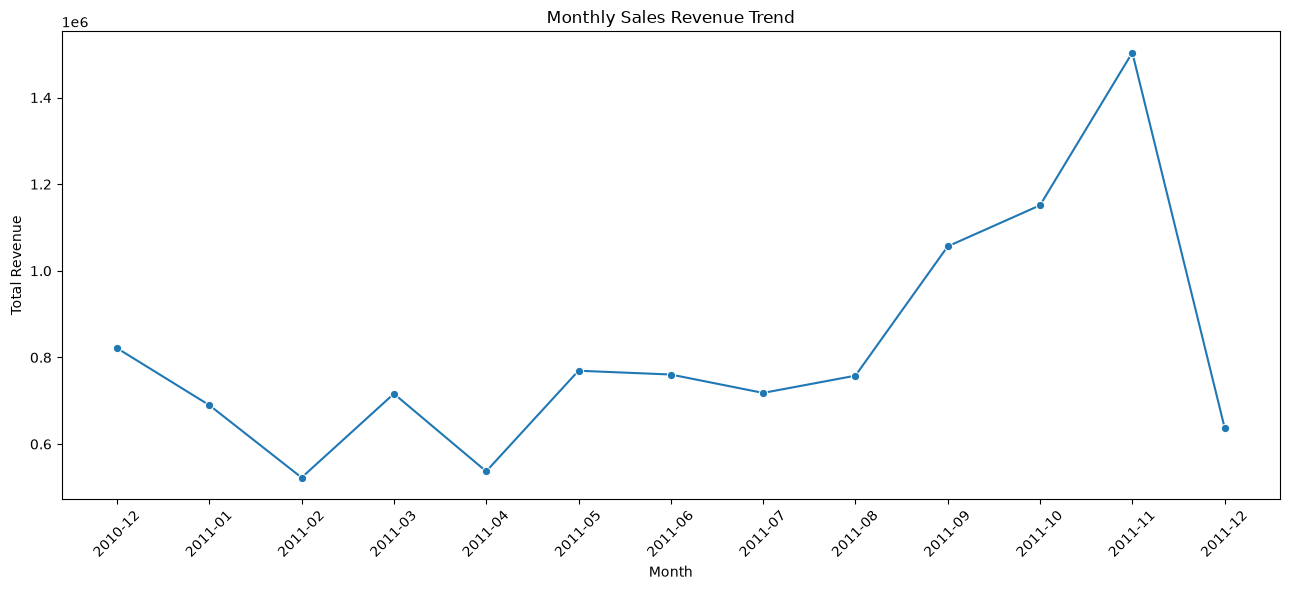

In [25]:

plt.figure(figsize=(13, 6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Total_Revenue",
    marker="o"
)

plt.title("Monthly Sales Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    "../outputs/figures/monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [26]:

monthly_sales.to_csv(
    "../outputs/cleaned_data/monthly_sales_analysis.csv",
    index=False
)

print("Monthly sales analysis saved successfully!")


Monthly sales analysis saved successfully!


## 7. COUNTRY-WISE SALES ANALYSIS

7.1. Calculate sales by country

In [27]:

country_analysis = (
    sales_df.groupby("Country")
    .agg(
        Total_Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .sort_values("Total_Revenue", ascending=False)
)

print("Top 10 countries by revenue:")
display(country_analysis.head(10))


Top 10 countries by revenue:


,Total_Revenue,Total_Quantity,Unique_Invoices
Country,,,
United Kingdom,9001744.094,4646906,18019
Netherlands,285446.340,200361,94
EIRE,283140.520,147007,288
Germany,228678.400,119154,457
France,209625.370,112060,392
Australia,138453.810,83891,57
Spain,61558.560,27933,90
Switzerland,57067.600,30617,54
Belgium,41196.340,23237,98


7.2. Create the country-wise chart

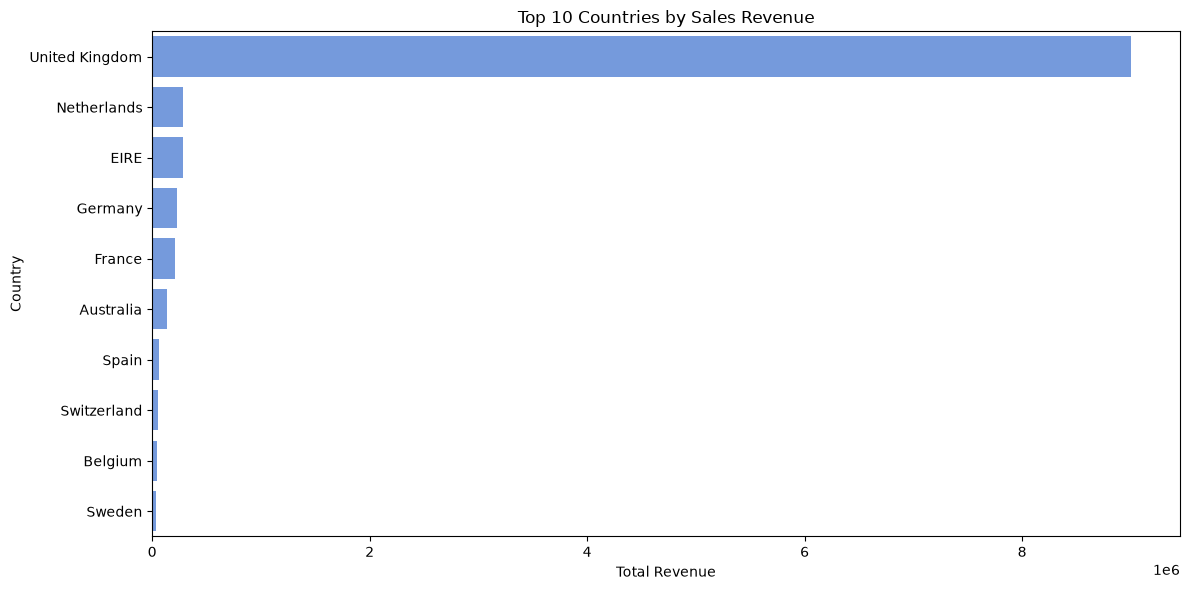

In [28]:

top_10_countries = country_analysis.head(10).reset_index()

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_countries,
    x="Total_Revenue",
    y="Country",
    color="cornflowerblue"
)

plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/top_10_countries.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


7.3. Save the results

In [29]:

country_analysis.to_csv(
    "../outputs/cleaned_data/country_analysis.csv"
)

print("Country analysis saved successfully!")


Country analysis saved successfully!


## 8. ANALYZE PRICE VERSES QUANTITY

8.1. Calculate the correlation

In [30]:

price_quantity_corr = sales_df[
    ["UnitPrice", "Quantity", "Revenue"]
].corr()

print("Correlation matrix:")
display(price_quantity_corr)

print(
    "Correlation between unit price and quantity:",
    round(price_quantity_corr.loc["UnitPrice", "Quantity"], 3)
)


Correlation matrix:


,UnitPrice,Quantity,Revenue
UnitPrice,1.000000,-0.003788,0.137381
Quantity,-0.003788,1.000000,0.907402
Revenue,0.137381,0.907402,1.000000


Correlation between unit price and quantity: -0.004


8.2. Plot price v/s quantity

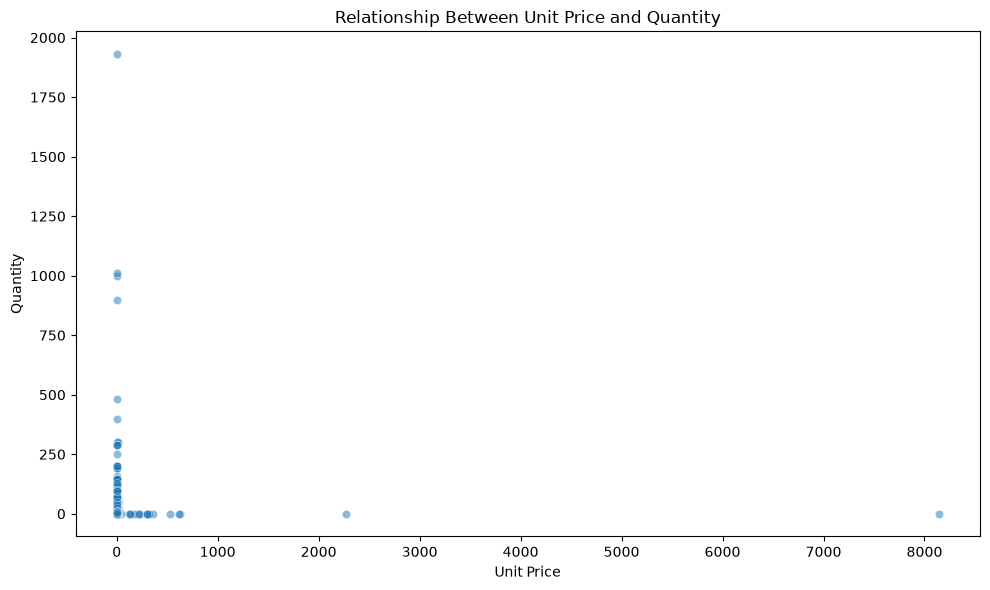

In [31]:

plot_df = sales_df.sample(
    n=min(5000, len(sales_df)),
    random_state=42
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=plot_df,
    x="UnitPrice",
    y="Quantity",
    alpha=0.5
)

plt.title("Relationship Between Unit Price and Quantity")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")
plt.tight_layout()

plt.savefig(
    "../outputs/figures/price_vs_quantity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 9. EXPORT ALL ANALYSIS RESULTS

In [32]:

from pathlib import Path

output_dir = Path("../outputs/cleaned_data")
output_dir.mkdir(parents=True, exist_ok=True)

product_analysis.to_csv(output_dir / "product_analysis.csv")
customer_analysis.to_csv(output_dir / "customer_analysis.csv")
monthly_sales.to_csv(output_dir / "monthly_sales_analysis.csv", index=False)
country_analysis.to_csv(output_dir / "country_analysis.csv")

print("All analysis tables saved successfully!")
print("Charts are saved in ../outputs/figures/")


All analysis tables saved successfully!
Charts are saved in ../outputs/figures/
